This notebook builds two models to predict weekly Theater District taxi trips from Broadway attendance and calendar features: Linear Regression and Random Forest. Trained on 2023, tested on 2024.

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

analysis_ready_dir = "../data/analysis_ready"
plot_data = pd.read_csv(f"{analysis_ready_dir}/theater_district_weekly.csv", parse_dates=["week_ending"])
plot_data.head()

,week_ending,weekly_trips,weekly_fares,weekly_tips,ID,gross,attendance,% Capacity,_c5
0,2023-01-08,66721,1059553.76,187122.48,110,37394931.0,275834.0,0.92,NaN
1,2023-01-15,78114,1177701.36,228002.39,109,33859988.0,247667.0,0.93,NaN
2,2023-01-22,76255,1188576.17,232831.13,108,25835362.0,204847.0,0.94,NaN
3,2023-01-29,75684,1159828.03,225532.54,107,25705039.0,206578.0,0.94,NaN
4,2023-02-05,74676,1141269.95,220014.48,106,23518702.0,195520.0,0.93,NaN


Build the features and split into train/test by date, not randomly.

In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_data = plot_data.copy().sort_values("week_ending").reset_index(drop=True)
model_data["month"] = model_data["week_ending"].dt.month
model_data["week_of_year"] = model_data["week_ending"].dt.isocalendar().week.astype(int)
model_data["is_holiday_season"] = model_data["month"].isin([11, 12]).astype(int)

features = ["attendance", "gross", "month", "week_of_year", "is_holiday_season"]
target = "weekly_trips"

train = model_data[model_data["week_ending"] < "2024-01-01"]
test = model_data[model_data["week_ending"] >= "2024-01-01"]

X_train, y_train = train[features], train[target]
X_test, y_test = test[features], test[target]

print(f"Train weeks: {len(train)} (2023)   Test weeks: {len(test)} (2024)")

Train weeks: 52 (2023)   Test weeks: 52 (2024)


Fit both models and check the errors on the test set.

In [39]:
lin_model = LinearRegression().fit(X_train, y_train)
lin_preds = lin_model.predict(X_test)

rf_model = RandomForestRegressor(n_estimators=200, max_depth=4, random_state=7).fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:20s}  MAE = {mae:8.0f}   RMSE = {rmse:8.0f}   R2 = {r2:.3f}")

report("Linear Regression", y_test, lin_preds)
report("Random Forest", y_test, rf_preds)

Linear Regression     MAE =     5885   RMSE =     7166   R2 = 0.369
Random Forest         MAE =     6517   RMSE =     8784   R2 = 0.051


Plot actual vs predicted trips.

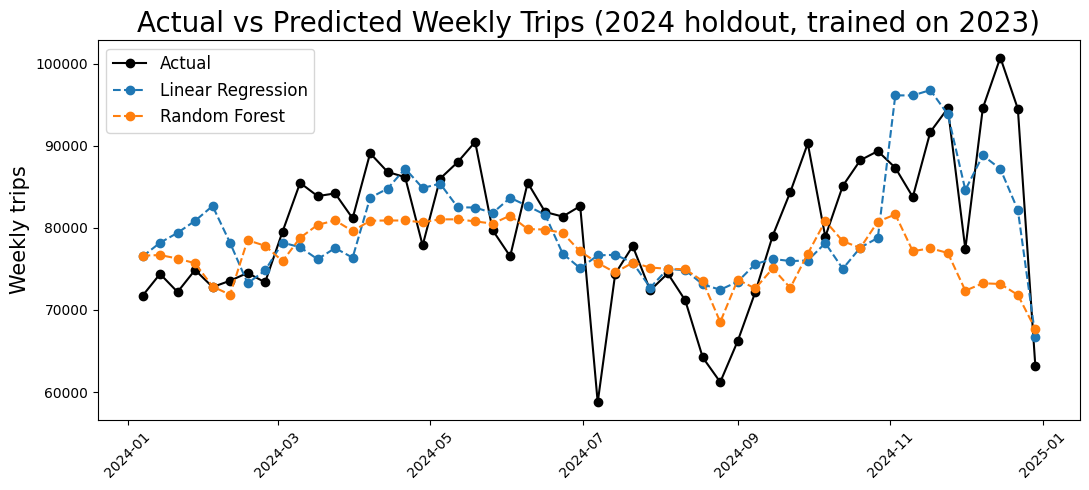

In [40]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(test["week_ending"], y_test, marker="o", label="Actual", color="black")
ax.plot(test["week_ending"], lin_preds, marker="o", label="Linear Regression", linestyle="--")
ax.plot(test["week_ending"], rf_preds, marker="o", label="Random Forest", linestyle="--")
ax.set_title("Actual vs Predicted Weekly Trips (2024 holdout, trained on 2023)", fontsize=20)
ax.set_ylabel("Weekly trips", fontsize=15)
ax.legend(fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("../plots/model_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

Check which features the Random Forest relied on most.

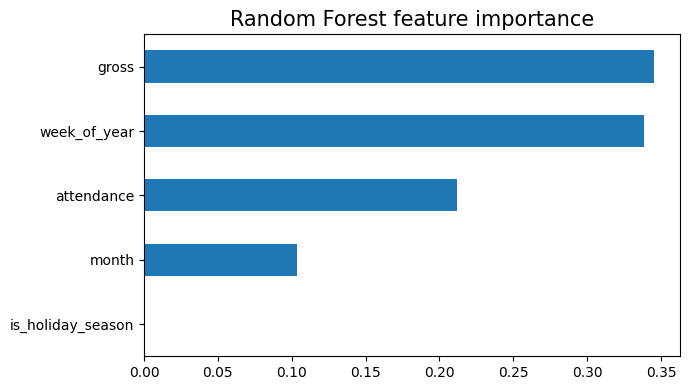

In [41]:
importances = pd.Series(rf_model.feature_importances_, index=features).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
importances.plot(kind="barh", ax=ax)
ax.set_title("Random Forest feature importance", fontsize=15)
plt.tight_layout()
plt.savefig("../plots/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()